<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula26d%20-%20cost%20functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

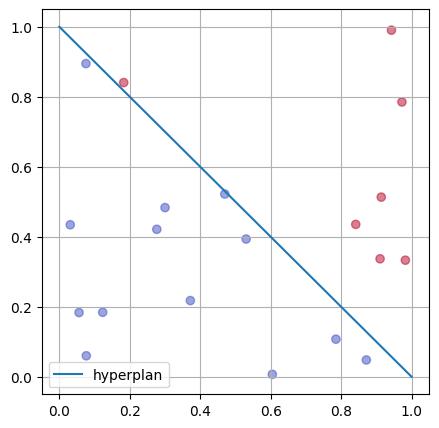

In [5]:
import numpy as np
from matplotlib import pyplot as plt

def create_dataset(n=20, coefs=[1, 1], intercept=-1):
  X = np.random.rand(n, 2)
  y = X @ coefs + intercept
  y = np.sign(y)
  return X, y

def plot_dataset(X, y):
  plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", alpha=0.5)
  plt.grid(True)

def plot_hyperplan(coefs, intercept, legend="hyperplan"):
  xs = np.array([0,1])
  ys = -(coefs[0] * xs + intercept) / coefs[1]
  plt.plot(xs, ys, label=legend)
  plt.legend()

coefs = [1, 1]
intercept = -1
X, y = create_dataset(20, coefs, intercept)

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept)
plt.show()

In [69]:
from abc import ABC, abstractstaticmethod

class CostFunction(ABC):
  @abstractstaticmethod
  def get_cost(y_true, logits):
    pass
  @abstractstaticmethod
  def get_gradient(y_true, logits):
    pass

class WidrowHoff(CostFunction):
  @staticmethod
  def get_cost(y_true, logits):
    return np.mean((y_true - logits)**2)
  @staticmethod
  def get_gradient(y_true, logits):
    return y_true - logits

In [70]:
wh = WidrowHoff()
y_perf = X @ coefs + intercept
print(wh.get_cost(y, y_perf))
print(wh.get_gradient(y, y_perf))

0.4766641843340159
[-0.2394259  -0.99179129 -0.8925695  -0.69797959 -0.30728332  0.06694487
 -0.78349368 -0.97031204 -0.58964294 -0.1366193  -0.61155594 -0.92382177
  0.75245573 -0.46531089  0.68459375  0.24234939  0.72318552  0.57286455
 -0.91954322  0.9765005 ]


In [89]:
from abc import ABC, abstractmethod

class Optimizer(ABC):
  @abstractmethod
  def get_w(self, X, y):
    pass

def include_bias(X):
  return np.c_[np.ones((X.shape[0],1)), X]

class SGD(Optimizer):
  def __init__(self, max_iter=1000, learning_rate=0.05,
               cost_function=WidrowHoff()):
    self.max_iter = max_iter
    self.learning_rate = learning_rate
    self.cost_function = cost_function

  def get_w(self, X, y):
    Xb = include_bias(X)
    y = y.reshape(-1)
    w = np.random.rand(Xb.shape[1])
    for _ in range(self.max_iter):
      logits = Xb @ w
      cost = self.cost_function.get_cost(y, logits)
      grad = self.cost_function.get_gradient(y, logits)
      w += self.learning_rate * Xb.T @ grad
      if cost == 0:
        break
    return w

sgd = SGD()
w = sgd.get_w(X, y)
print(w)

[-1.79604835  1.64552292  1.57980319]


accuracy: 0.95
coefs: [1.64552292 1.57980319]


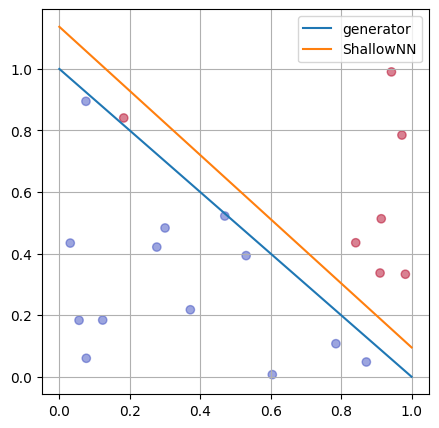

In [90]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

class ShallowNN(BaseEstimator, ClassifierMixin):
  def __init__(self, optimizer=SGD()):
    self.optimizer = optimizer

  def fit(self, X, y):
    Xb = include_bias(X)
    y = y.reshape(-1)
    self.w = self.optimizer.get_w(X, y)
    self.intercept = self.w[0]
    self.coefs = self.w[1:]
    return self

  def pre_activation(self, X):
    Xb = include_bias(X)
    logits = Xb @ self.w
    return logits

  def predict(self, X):
    logits = self.pre_activation(X)
    y_pred = np.sign(logits)
    return y_pred

clf = ShallowNN()
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "ShallowNN")
plt.show()

In [74]:
class SmoothedSurrogate(CostFunction):
  @staticmethod
  def get_cost(y_true, logits):
    return np.sum(np.maximum(np.zeros(y.shape), -y * logits))
  @staticmethod
  def get_gradient(y_true, logits):
    return y_true - np.sign(logits)

accuracy: 1.0
coefs: [1.21524177 1.39736694]


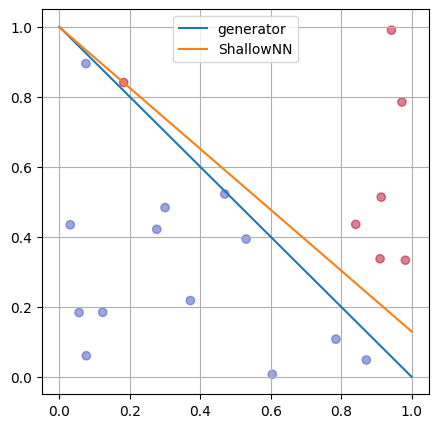

In [96]:
clf = ShallowNN(SGD(cost_function=SmoothedSurrogate()))
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "ShallowNN")
plt.show()

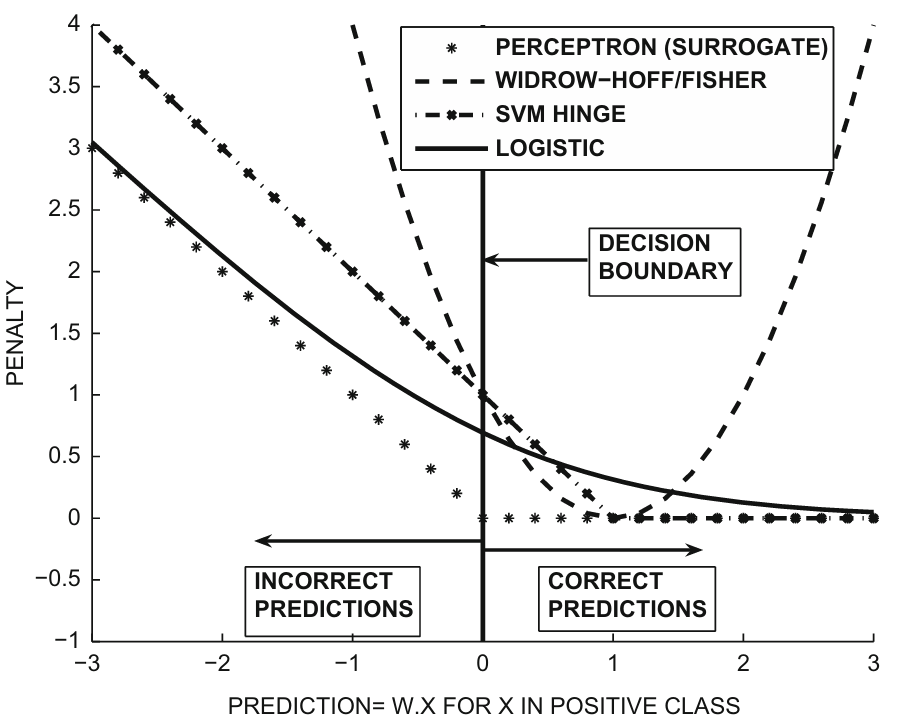

In [102]:
class HingeLoss(CostFunction):
  @staticmethod
  def get_cost(y_true, logits):
    return np.sum(np.maximum(np.zeros(y.shape), 1 - y * logits))
  @staticmethod
  def get_gradient(y_true, logits):
    marginal_errors = (y_true * logits) < 1
    marginal_ys = np.copy(y)
    marginal_ys[~marginal_errors] = 0
    return marginal_ys

accuracy: 0.95
coefs: [7.70671322 7.90327776]


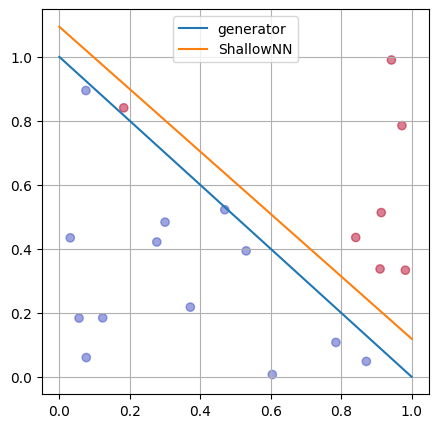

In [108]:
clf = ShallowNN(SGD(cost_function=HingeLoss()))
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "ShallowNN")
plt.show()